# 04 — Modélisation : KNN, SVM et Random Forest

On entraîne les trois familles de modèles demandées sur les vecteurs de 1840 valeurs construits en phase 3,
on règle leurs hyperparamètres, puis on retient le meilleur.

**Protocole (identique pour les trois modèles)**

| Ensemble | Rôle dans ce notebook |
|---|---|
| train (6211 régions) | apprentissage (`fit`) — y compris le StandardScaler et la PCA |
| validation **propre** (1666 régions, sans les quasi-doublons) | choix des hyperparamètres et du modèle |
| test (785 régions) | **jamais utilisé ici** — réservé à l'évaluation finale (phase 5) |

- **Métrique de choix : F1 macro** (moyenne des F1 des 6 classes). L'accuracy favoriserait la classe majoritaire *scratch* (41 %).
- Le déséquilibre est compensé par `class_weight="balanced"` (SVM, Random Forest). KNN n'a pas cette option : on teste `weights="distance"`.
- Code réutilisable dans `src/models/` : `pipelines.py` (construction des modèles), `train.py` (recherche + sauvegarde),
  `inference.py` (prédiction, utilisé par l'API).

La recherche complète est lancée par `python -m src.models.train` (≈ 10 min) et ses résultats sont enregistrés dans
`reports/modeling/search_results.csv`. Ce notebook relit ce fichier s'il existe (mettre `FORCE_SEARCH = True` pour tout recalculer).
Durée d'exécution du notebook : environ 3 minutes.

In [1]:
import sys, json, time, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

from src.models import train
from src.models.pipelines import SEARCH_SPACES, build_pipeline
from src.models.inference import DamagePredictor

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
CLASS_ORDER = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
MODEL_COLORS = {"knn": "#4C72B0", "svm": "#DD8452", "rf": "#55A868", "baseline": "#8C8C8C"}
MODEL_NAMES = {"knn": "KNN", "svm": "SVM (RBF)", "rf": "Random Forest"}
FORCE_SEARCH = False

X, y, meta, configs = train.load_dataset()
masks = train.split_masks(meta)
TR, VA = masks["train"], masks["val_clean"]
print("X :", X.shape, "| configuration :", configs["preprocess"])
print({k: int(v.sum()) for k, v in masks.items()})

X : (8740, 1840) | configuration : {'patch_size': 128, 'margin': 0.0, 'resize_mode': 'stretch'}
{'train': 6211, 'val': 1744, 'val_clean': 1666, 'test': 785, 'test_clean': 761}


## 1. Encodage de la cible (LabelEncoder)

La classe à prédire est un texte ; les modèles manipulent des entiers. Le `LabelEncoder` (ordre alphabétique) est
**enregistré avec le modèle** pour que l'API retraduise exactement de la même façon l'entier prédit en nom de classe.

In [2]:
encoder = LabelEncoder().fit(y)
pd.DataFrame({"classe": encoder.classes_, "code": range(len(encoder.classes_)),
              "régions train": [int((y[TR] == c).sum()) for c in encoder.classes_],
              "régions val propre": [int((y[VA] == c).sum()) for c in encoder.classes_]})

,classe,code,régions train,régions val propre
0,crack,0,651,166
1,dent,1,1806,490
2,glass shatter,2,475,128
3,lamp broken,3,494,136
4,scratch,4,2560,688
5,tire flat,5,225,58


## 2. Baselines : le score à battre

Avant tout modèle, on mesure ce que donne une prédiction « bête » :
- **classe majoritaire** : toujours prédire *scratch* ;
- **aléatoire stratifié** : tirer une classe au hasard selon les fréquences du train.

Un modèle qui ne fait pas nettement mieux n'a rien appris.

In [3]:
rows = []
for strategy in ["most_frequent", "stratified"]:
    dummy = DummyClassifier(strategy=strategy, random_state=0).fit(X[TR], y[TR])
    p = dummy.predict(X[VA])
    rows.append({"baseline": strategy, "accuracy val": accuracy_score(y[VA], p),
                 "F1 macro val": f1_score(y[VA], p, average="macro")})
baselines = pd.DataFrame(rows).round(3)
BASELINE_F1 = baselines["F1 macro val"].max()
baselines

,baseline,accuracy val,F1 macro val
0,most_frequent,0.413,0.097
1,stratified,0.276,0.163


La classe majoritaire obtient une accuracy trompeuse (≈ 0,41) mais un F1 macro très bas : elle ignore 5 classes sur 6.
C'est pour cela que le F1 macro est la métrique de choix.

## 3. Recherche des hyperparamètres

Pour chaque combinaison de la grille : entraînement sur train, F1 macro sur la validation propre.
C'est une recherche exhaustive (« grid search ») avec un ensemble de validation fixe : il est déjà séparé du train
et débarrassé des quasi-doublons, donc plus fiable qu'une validation croisée qui mélangerait des photos presque identiques.

In [4]:
pd.DataFrame([{"modèle": MODEL_NAMES[m], "grille": " ; ".join(json.dumps(g) for g in grids)}
              for m, grids in SEARCH_SPACES.items()]).style.hide(axis="index")

modèle,grille
KNN,"{""pca"": [20, 50, 100, null], ""n_neighbors"": [1, 3, 5, 9, 15, 25], ""weights"": [""uniform"", ""distance""], ""metric"": [""euclidean"", ""cosine""]}"
SVM (RBF),"{""pca"": [50, 100, 200, 400], ""C"": [1, 3, 10, 30, 100], ""gamma_mult"": [0.5, 1, 2]} ; {""pca"": [null], ""C"": [10, 30], ""gamma_mult"": [1]}"
Random Forest,"{""n_estimators"": [300], ""max_features"": [""sqrt"", ""log2""], ""min_samples_leaf"": [1, 3], ""max_depth"": [null, 20], ""class_weight"": [""balanced"", ""balanced_subsample""]}"


In [5]:
t0 = time.time()
results = train.run_search(X, y, masks, force=FORCE_SEARCH)
print(f"{len(results)} configurations ({time.time() - t0:.0f} s ; 0 s = relu depuis reports/modeling/search_results.csv)")
results.groupby("model").agg(configurations=("val_f1", "size"), F1_val_min=("val_f1", "min"),
                             F1_val_max=("val_f1", "max"), temps_total_s=("fit_s", "sum")).round(3)

174 configurations (0 s ; 0 s = relu depuis reports/modeling/search_results.csv)


,configurations,F1_val_min,F1_val_max,temps_total_s
model,,,,
knn,96,0.416,0.659,3.28
rf,16,0.573,0.738,93.24
svm,62,0.718,0.807,1543.96


### 3.1 KNN

Hyperparamètres : nombre de voisins `k`, pondération (`uniform` : chaque voisin vote pareil ; `distance` : les plus proches comptent plus),
distance (euclidienne ou cosinus) et nombre de composantes de la PCA (`None` = les 1840 variables standardisées).

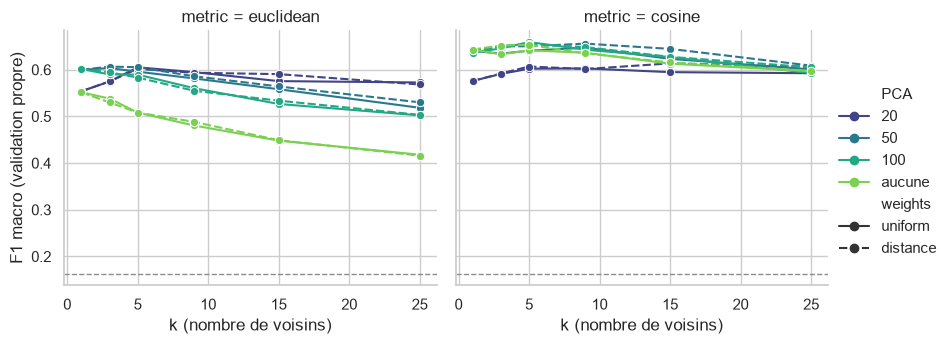

,pca,n_neighbors,weights,metric,val_f1,train_f1
64,100.0,5.0,uniform,cosine,0.659,0.79
43,50.0,9.0,distance,cosine,0.656,1.00
65,100.0,5.0,distance,cosine,0.654,1.00
89,NaN,5.0,distance,cosine,0.653,1.00
87,NaN,3.0,distance,cosine,0.652,1.00
63,100.0,3.0,distance,cosine,0.651,1.00
39,50.0,3.0,distance,cosine,0.650,1.00
41,50.0,5.0,distance,cosine,0.650,1.00


In [6]:
knn = results[results["model"] == "knn"].copy()
knn["PCA"] = knn["pca"].fillna(0).astype(int).replace(0, "aucune").astype(str)
g = sns.relplot(data=knn, x="n_neighbors", y="val_f1", hue="PCA", style="weights", col="metric",
                kind="line", marker="o", height=3.6, aspect=1.2, palette="viridis")
g.set_axis_labels("k (nombre de voisins)", "F1 macro (validation propre)")
for ax in g.axes.flat:
    ax.axhline(BASELINE_F1, color=MODEL_COLORS["baseline"], ls="--", lw=1)
plt.show()
knn.sort_values("val_f1", ascending=False)[["pca", "n_neighbors", "weights", "metric", "val_f1", "train_f1"]].head(8).round(3)

### 3.2 SVM (noyau RBF)

- `C` : tolérance aux erreurs d'entraînement. Petit C = frontière simple (risque de sous-apprentissage) ; grand C = colle au train (risque de surapprentissage).
- `gamma` : portée d'influence de chaque exemple, exprimée en multiple de la valeur par défaut de scikit-learn (`gamma_mult = 1`).
- `pca` : nombre de composantes gardées avant le SVM (accélère fortement l'entraînement).

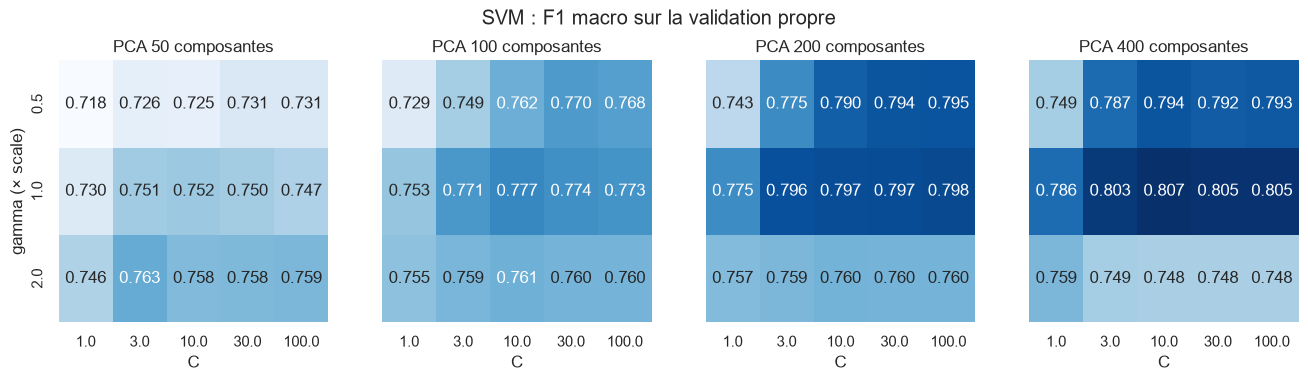

Sans PCA (1840 variables) :


,C,gamma_mult,val_f1,train_f1,fit_s
156,10.0,1.0,0.803,1.0,57.43
157,30.0,1.0,0.802,1.0,57.55


In [7]:
svm = results[results["model"] == "svm"]
grid = svm[svm["pca"].notna()]
pcas = sorted(grid["pca"].unique())
fig, axes = plt.subplots(1, len(pcas), figsize=(4 * len(pcas), 3.4), sharey=True)
vmin, vmax = grid["val_f1"].min(), grid["val_f1"].max()
for ax, p in zip(axes, pcas):
    piv = grid[grid["pca"] == p].pivot(index="gamma_mult", columns="C", values="val_f1")
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", vmin=vmin, vmax=vmax, cbar=False, ax=ax)
    ax.set_title(f"PCA {int(p)} composantes"); ax.set_xlabel("C"); ax.set_ylabel("gamma (× scale)" if p == pcas[0] else "")
fig.suptitle("SVM : F1 macro sur la validation propre", y=1.03)
plt.show()
print("Sans PCA (1840 variables) :")
svm[svm["pca"].isna()][["C", "gamma_mult", "val_f1", "train_f1", "fit_s"]].round(3)

### 3.3 Random Forest

- `max_features` : nombre de variables tirées au hasard à chaque nœud (`sqrt` ≈ 43, `log2` ≈ 11) — plus il est petit, plus les arbres sont différents.
- `min_samples_leaf`, `max_depth` : limitent la taille des arbres (régularisation).
- `class_weight` : `balanced` (poids calculés sur tout le train) ou `balanced_subsample` (recalculés pour chaque arbre).

In [8]:
rf = results[results["model"] == "rf"]
rf.sort_values("val_f1", ascending=False)[["max_features", "min_samples_leaf", "max_depth", "class_weight",
                                           "val_f1", "train_f1", "fit_s"]].round(3)

,max_features,min_samples_leaf,max_depth,class_weight,val_f1,train_f1,fit_s
158,sqrt,1.0,NaN,balanced,0.738,0.999,9.00
164,log2,1.0,20.0,balanced,0.737,0.999,2.46
167,sqrt,3.0,NaN,balanced_subsample,0.734,1.000,9.49
161,log2,3.0,NaN,balanced,0.732,0.994,2.43
162,sqrt,1.0,20.0,balanced,0.732,0.999,8.22
171,sqrt,3.0,20.0,balanced_subsample,0.730,1.000,9.32
165,log2,3.0,20.0,balanced,0.728,0.994,2.35
160,log2,1.0,NaN,balanced,0.726,1.000,2.42
163,sqrt,3.0,20.0,balanced,0.722,0.987,7.33
159,sqrt,3.0,NaN,balanced,0.722,0.988,7.43


## 4. Comparaison des trois meilleurs modèles

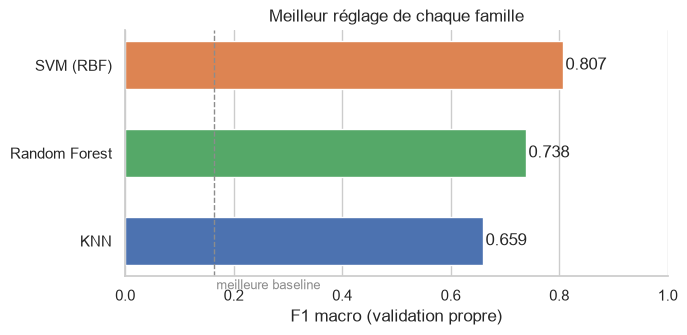

,model,val_f1,train_f1,gap,fit_s,predict_val_s,params
0,svm,0.807,1.000,0.193,49.94,10.58,"{""model"": ""svm"", ""pca"": 400, ""C"": 10, ""gamma"":..."
1,rf,0.738,0.999,0.261,9.00,0.18,"{""model"": ""rf"", ""n_estimators"": 300, ""max_feat..."
2,knn,0.659,0.790,0.131,0.01,0.52,"{""model"": ""knn"", ""pca"": 100, ""n_neighbors"": 5,..."


In [9]:
best = train.best_per_model(results)
fig, ax = plt.subplots(figsize=(7, 3.2))
names = [MODEL_NAMES[m] for m in best["model"]]
ax.barh(names, best["val_f1"], color=[MODEL_COLORS[m] for m in best["model"]], height=0.55)
for i, v in enumerate(best["val_f1"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.axvline(BASELINE_F1, color=MODEL_COLORS["baseline"], ls="--", lw=1)
ax.text(BASELINE_F1 + 0.005, len(best) - 0.45, "meilleure baseline", color=MODEL_COLORS["baseline"], fontsize=9)
ax.set_xlim(0, 1); ax.grid(axis="y", visible=False); ax.invert_yaxis(); ax.set_xlabel("F1 macro (validation propre)")
ax.set_title("Meilleur réglage de chaque famille")
plt.show()
best[["model", "val_f1", "train_f1", "gap", "fit_s", "predict_val_s", "params"]].round(3)

Pour analyser chaque modèle en détail, on réentraîne son meilleur réglage **sur le train seul** et on prédit la validation propre
(le modèle final, lui, sera réentraîné sur train + val à la section 7).

In [10]:
fitted, preds = {}, {}
for _, row in best.iterrows():
    params = json.loads(row["params"])
    t0 = time.time()
    fitted[row["model"]] = build_pipeline(params).fit(X[TR], y[TR])
    preds[row["model"]] = fitted[row["model"]].predict(X[VA])
    print(f"{MODEL_NAMES[row['model']]:14s} F1 macro val = {f1_score(y[VA], preds[row['model']], average='macro'):.3f}"
          f"  ({time.time() - t0:.0f} s)")

per_class = pd.DataFrame({MODEL_NAMES[m]: f1_score(y[VA], p, labels=CLASS_ORDER, average=None) for m, p in preds.items()},
                         index=CLASS_ORDER)
per_class["régions val"] = [int((y[VA] == c).sum()) for c in CLASS_ORDER]
per_class.round(3)

SVM (RBF)      F1 macro val = 0.807  (17 s)


Random Forest  F1 macro val = 0.738  (9 s)


KNN            F1 macro val = 0.659  (1 s)


,SVM (RBF),Random Forest,KNN,régions val
dent,0.769,0.694,0.595,490
scratch,0.804,0.730,0.712,688
crack,0.606,0.583,0.523,166
glass shatter,0.848,0.766,0.680,128
lamp broken,0.857,0.741,0.569,136
tire flat,0.955,0.916,0.877,58


## 5. Le modèle retenu en détail (validation propre)

Modèle retenu : SVM (RBF)

               precision    recall  f1-score   support

         dent      0.764     0.773     0.769       490
      scratch      0.764     0.849     0.804       688
        crack      0.769     0.500     0.606       166
glass shatter      0.869     0.828     0.848       128
  lamp broken      0.902     0.816     0.857       136
    tire flat      1.000     0.914     0.955        58

     accuracy                          0.790      1666
    macro avg      0.845     0.780     0.807      1666
 weighted avg      0.792     0.790     0.787      1666



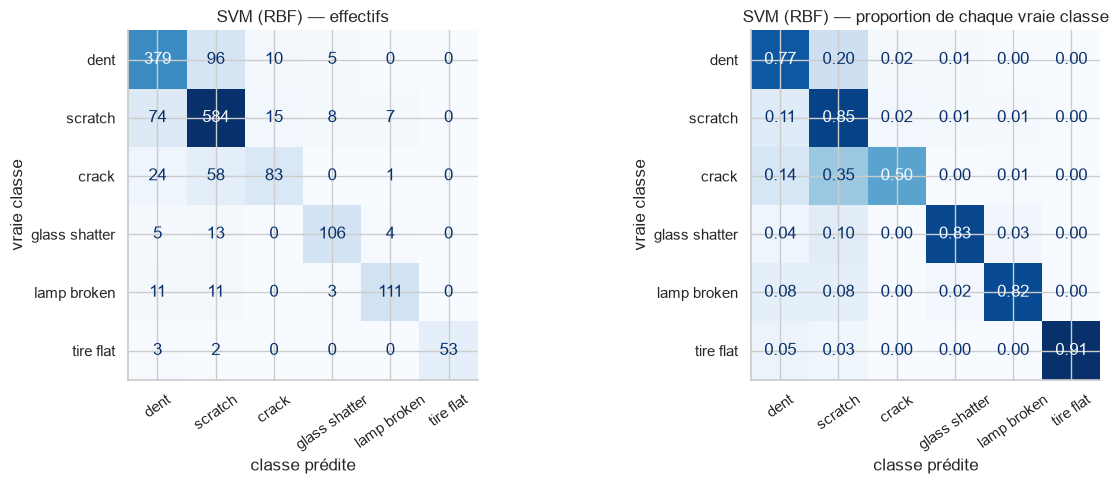

In [11]:
SELECTED = best.loc[0, "model"]
print(f"Modèle retenu : {MODEL_NAMES[SELECTED]}\n")
print(classification_report(y[VA], preds[SELECTED], labels=CLASS_ORDER, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, norm, title in [(axes[0], None, "effectifs"), (axes[1], "true", "proportion de chaque vraie classe")]:
    ConfusionMatrixDisplay.from_predictions(y[VA], preds[SELECTED], labels=CLASS_ORDER, normalize=norm, cmap="Blues",
                                            values_format=".2f" if norm else "d", ax=ax, colorbar=False)
    ax.set_title(f"{MODEL_NAMES[SELECTED]} — {title}"); ax.set_xlabel("classe prédite"); ax.set_ylabel("vraie classe")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

In [12]:
cm = pd.DataFrame(confusion_matrix(y[VA], preds[SELECTED], labels=CLASS_ORDER), index=CLASS_ORDER, columns=CLASS_ORDER)
off = cm.where(~np.eye(len(CLASS_ORDER), dtype=bool)).stack().sort_values(ascending=False)
print("Confusions les plus fréquentes (vraie -> prédite) :")
off.head(6).astype(int)

Confusions les plus fréquentes (vraie -> prédite) :


dent           scratch    96
scratch        dent       74
crack          scratch    58
               dent       24
scratch        crack      15
glass shatter  scratch    13
dtype: int64

## 6. Surapprentissage : courbe d'apprentissage

Le score d'entraînement est presque parfait pour les trois modèles alors que la validation est nettement plus basse.
Pour savoir si **plus de données** aiderait, on entraîne le modèle retenu sur 10 %, 25 %, 50 %, 75 % puis 100 % du train
(tirages stratifiés) et on mesure le F1 macro sur le sous-ensemble d'entraînement et sur la validation propre.

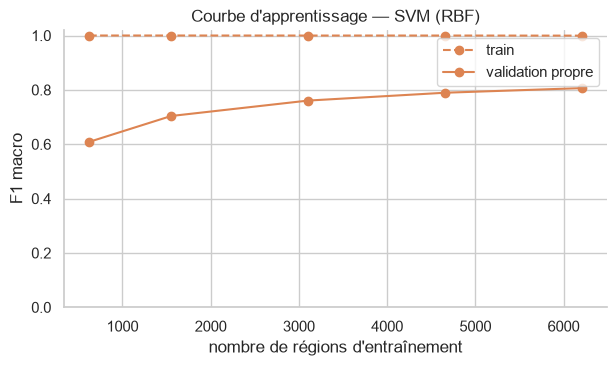

,fraction,régions,train,validation propre
0,0.10,621,1.0,0.608
1,0.25,1552,1.0,0.704
2,0.50,3105,1.0,0.761
3,0.75,4658,1.0,0.789
4,1.00,6211,1.0,0.807


In [13]:
from sklearn.model_selection import train_test_split
params_sel = json.loads(best.loc[0, "params"])
idx_tr = np.flatnonzero(TR)
curve = []
for frac in [0.1, 0.25, 0.5, 0.75, 1.0]:
    sub = idx_tr if frac == 1.0 else train_test_split(idx_tr, train_size=frac, stratify=y[idx_tr], random_state=0)[0]
    pipe = build_pipeline(params_sel).fit(X[sub], y[sub])
    curve.append({"fraction": frac, "régions": len(sub),
                  "train": f1_score(y[sub], pipe.predict(X[sub]), average="macro"),
                  "validation propre": f1_score(y[VA], pipe.predict(X[VA]), average="macro")})
curve = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(7, 3.6))
for col, ls in [("train", "--"), ("validation propre", "-")]:
    ax.plot(curve["régions"], curve[col], ls, marker="o", color=MODEL_COLORS[SELECTED], label=col)
ax.set_xlabel("nombre de régions d'entraînement"); ax.set_ylabel("F1 macro"); ax.set_ylim(0, 1.02)
ax.set_title(f"Courbe d'apprentissage — {MODEL_NAMES[SELECTED]}"); ax.legend()
plt.show()
curve.round(3)

## 7. Modèles finaux sauvegardés

`python -m src.models.train` réentraîne le meilleur réglage de chaque famille **sur train + val** (plus de données = meilleur modèle,
le choix des hyperparamètres étant déjà fait) et l'enregistre avec joblib dans `models/` :

- le pipeline complet (StandardScaler → PCA → classifieur), le `LabelEncoder`, les configurations de prétraitement et de descripteurs ;
- pour le SVM, une calibration de Platt (`CalibratedClassifierCV`) fournit des probabilités, affichées par l'application ;
- `models/selection.json` indique le modèle retenu, chargé par défaut par l'API.

Ces fichiers ne sont **pas versionnés** (modèles volumineux) : chaque membre de l'équipe les régénère avec la commande ci-dessus.

In [14]:
selection = json.loads(train.SELECTION_JSON.read_text(encoding="utf-8"))
print("Modèle retenu :", selection["selected"])
pd.DataFrame(selection["models"]).T[["file", "val_clean_macro_f1", "size_mb"]]

Modèle retenu : svm


,file,val_clean_macro_f1,size_mb
svm,svm.joblib,0.8065,15.3
rf,rf.joblib,0.7383,13.6
knn,knn.joblib,0.6592,3.7


**Vérification de bout en bout** : on charge le modèle retenu comme le fera l'API et on prédit une région à partir de la photo
d'origine. Ce n'est **pas** une évaluation (le modèle final a vu la validation) : on vérifie seulement que le chargement,
le prétraitement partagé et les probabilités fonctionnent. L'évaluation sur le test est l'objet de la phase 5.

In [15]:
from src.data.coco_loader import image_dir
from src.data.image_io import read_image_rgb
predictor = DamagePredictor.load()
row = meta[VA].iloc[0]
img = read_image_rgb(image_dir(row["split"]) / row["file_name"])
regions = pd.read_csv(PROJECT_ROOT / "reports" / "cleaning" / "regions.csv")
r = regions[(regions["split"] == row["split"]) & (regions["annotation_id"] == row["annotation_id"])].iloc[0]  # id unique par split
bbox = (r["bbox_x"], r["bbox_y"], r["bbox_w"], r["bbox_h"])
assert np.allclose(predictor.features_of(img, bbox), X[meta.index[VA][0]])   # mêmes descripteurs qu'à l'entraînement
out = predictor.predict(img, bbox)
print("vraie classe :", row["category_name"])
pd.DataFrame(out["top"]).round(3)

vraie classe : crack


,label,probability
0,crack,0.743
1,scratch,0.222
2,dent,0.030


## 8. Synthèse
| Modèle | Meilleur réglage | F1 macro val propre | F1 train |
|---|---|---|---|
| **SVM (RBF)** | PCA 400, C = 10, gamma = scale | **0,807** | 1,000 |
| Random Forest | 300 arbres, max_features = sqrt, arbres complets, balanced | 0,738 | 0,999 |
| KNN | PCA 100, k = 5, distance cosinus, vote uniforme | 0,659 | 0,790 |
| meilleure baseline | aléatoire stratifié | 0,163 | — |

- **Modèle retenu : SVM à noyau RBF** (F1 macro 0,807, accuracy 0,79 sur la validation propre), nettement devant le Random Forest
  et le KNN, et 5 fois mieux que la meilleure baseline. Il est le meilleur sur **chacune** des 6 classes.
- Le réglage retenu est au milieu de sa grille pour C et gamma ; pour la PCA, 400 composantes (0,807) et aucune PCA (0,803) sont équivalents,
  mais la PCA rend l'entraînement environ 6 fois plus rapide (16 s contre 94 s) : on la garde.
- **KNN** souffre de la grande dimension : la distance cosinus et la PCA l'aident, mais il plafonne à 0,66.
- **Classes difficiles** : *crack* (F1 0,61, rappel 0,50) est souvent pris pour *scratch* — deux dommages fins et allongés ;
  *dent* et *scratch* se confondent aussi (96 et 74 erreurs). *tire flat*, *lamp broken* et *glass shatter* sont bien reconnus (F1 ≥ 0,85).
- **Surapprentissage** : le SVM et le Random Forest sont parfaits sur le train. La courbe d'apprentissage du SVM monte encore
  (0,61 avec 10 % du train → 0,81 avec 100 %) : **plus de données améliorerait le modèle**. C'est pourquoi le modèle final est réentraîné sur train + val.
- Le modèle final (`models/svm.joblib`, 15 Mo) contient le pipeline, le LabelEncoder et les configurations ; il donne des probabilités calibrées.
  L'évaluation définitive sur le **test**, jamais utilisé jusqu'ici, est l'objet de la phase 5.